----
# **<font color="lightgreen" style="bold">Author :**
# **&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Mana Coulibaly               : COUM79090200**
# </font>
---

# **Importation des données**

In [2]:
import kaggle
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Définir l'ID du dataset
dataset_id = "anthonytherrien/depression-dataset"

# Télécharger et extraire les fichiers dans le dossier 'data/'
kaggle.api.dataset_download_files(dataset_id, path="data/", unzip=True)

print("Téléchargement terminé ! Les fichiers sont disponibles dans le dossier 'data/'.")


Dataset URL: https://www.kaggle.com/datasets/anthonytherrien/depression-dataset
Téléchargement terminé ! Les fichiers sont disponibles dans le dossier 'data/'.


In [ ]:
# Charger les données (remplacez 'data/filename.csv' par le vrai nom du fichier)
df = pd.read_csv("data/depression_data.csv")

# Afficher les premières lignes
print(df.head(5))

               Name  Age Marital Status    Education Level  \
0  Christine Barker   31        Married  Bachelor's Degree   
1  Jacqueline Lewis   55        Married        High School   
2    Shannon Church   78        Widowed    Master's Degree   
3    Charles Jordan   58       Divorced    Master's Degree   
4      Michael Rich   18         Single        High School   

   Number of Children Smoking Status Physical Activity Level  \
0                   2     Non-smoker                  Active   
1                   1     Non-smoker               Sedentary   
2                   1     Non-smoker               Sedentary   
3                   3     Non-smoker                Moderate   
4                   0     Non-smoker               Sedentary   

  Employment Status     Income Alcohol Consumption Dietary Habits  \
0        Unemployed   26265.67            Moderate       Moderate   
1          Employed   42710.36                High      Unhealthy   
2          Employed  125332.79     

In [5]:
# Dimensions du dataset
print("Taille du dataset :", df.shape)

# Vérifier les types de données
print(df.info())

# Résumé statistique des variables numériques
print(df.describe())

# Vérifier les valeurs uniques des colonnes catégorielles
for col in df.select_dtypes(include=['object']).columns:
    print(f"\nValeurs uniques de '{col}':")
    print(df[col].value_counts())


Taille du dataset : (413768, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413768 entries, 0 to 413767
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Name                          413768 non-null  object 
 1   Age                           413768 non-null  int64  
 2   Marital Status                413768 non-null  object 
 3   Education Level               413768 non-null  object 
 4   Number of Children            413768 non-null  int64  
 5   Smoking Status                413768 non-null  object 
 6   Physical Activity Level       413768 non-null  object 
 7   Employment Status             413768 non-null  object 
 8   Income                        413768 non-null  float64
 9   Alcohol Consumption           413768 non-null  object 
 10  Dietary Habits                413768 non-null  object 
 11  Sleep Patterns                413768 non-null  object 
 12  History of 

In [6]:
# Vérifier le nombre de valeurs manquantes
print(df.isnull().sum())

Name                            0
Age                             0
Marital Status                  0
Education Level                 0
Number of Children              0
Smoking Status                  0
Physical Activity Level         0
Employment Status               0
Income                          0
Alcohol Consumption             0
Dietary Habits                  0
Sleep Patterns                  0
History of Mental Illness       0
History of Substance Abuse      0
Family History of Depression    0
Chronic Medical Conditions      0
dtype: int64


In [7]:
# Vérifier les doublons
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


In [8]:
df.drop(columns='Name',inplace = True)
print(df.head(5))

   Age Marital Status    Education Level  Number of Children Smoking Status  \
0   31        Married  Bachelor's Degree                   2     Non-smoker   
1   55        Married        High School                   1     Non-smoker   
2   78        Widowed    Master's Degree                   1     Non-smoker   
3   58       Divorced    Master's Degree                   3     Non-smoker   
4   18         Single        High School                   0     Non-smoker   

  Physical Activity Level Employment Status     Income Alcohol Consumption  \
0                  Active        Unemployed   26265.67            Moderate   
1               Sedentary          Employed   42710.36                High   
2               Sedentary          Employed  125332.79                 Low   
3                Moderate        Unemployed    9992.78            Moderate   
4               Sedentary        Unemployed    8595.08                 Low   

  Dietary Habits Sleep Patterns History of Mental Illnes

In [9]:

df["Marital Status"].value_counts()

Marital Status
Married     240444
Single       72110
Widowed      68485
Divorced     32729
Name: count, dtype: int64

In [10]:

df["Smoking Status"].value_counts()

Smoking Status
Non-smoker    247416
Former        116184
Current        50168
Name: count, dtype: int64

In [11]:

df["Employment Status"].value_counts()

Employment Status
Employed      265659
Unemployed    148109
Name: count, dtype: int64

In [12]:

df["History of Mental Illness"].value_counts()

History of Mental Illness
No     287943
Yes    125825
Name: count, dtype: int64

In [13]:

df["History of Substance Abuse"].value_counts()

History of Substance Abuse
No     284880
Yes    128888
Name: count, dtype: int64

In [14]:

df["Family History of Depression"].value_counts()

Family History of Depression
No     302515
Yes    111253
Name: count, dtype: int64

In [15]:

df["Chronic Medical Conditions"].value_counts()

Chronic Medical Conditions
No     277561
Yes    136207
Name: count, dtype: int64

# **Prétraitement des données**

----
# <font color = "orange" style="bold">
# **1 - Données catégorielles ordinales**
# </font>
---

In [16]:
# Vérifier les valeurs uniques de chaque colonne
print("Education level:", df["Education Level"].unique())
print("Physical Activity level:", df["Physical Activity Level"].unique())
print("Alcohol Consumption:", df["Alcohol Consumption"].unique())
print("Dietary habits:", df["Dietary Habits"].unique())
print("Sleep patterns:", df["Sleep Patterns"].unique())

Education level: ["Bachelor's Degree" 'High School' "Master's Degree" 'Associate Degree'
 'PhD']
Physical Activity level: ['Active' 'Sedentary' 'Moderate']
Alcohol Consumption: ['Moderate' 'High' 'Low']
Dietary habits: ['Moderate' 'Unhealthy' 'Healthy']
Sleep patterns: ['Fair' 'Good' 'Poor']


In [17]:
# Définir les ordres pour chaque colonne
ordres = [
    ['High School', 'Associate Degree', "Bachelor's Degree", "Master's Degree", 'PhD'],  # Education level
    ['Sedentary', 'Moderate', 'Active'],  # Physical Activity level
    ['Low', 'Moderate', 'High'],  # Alcohol Consumption
    ['Unhealthy', 'Moderate', 'Healthy'],  # Dietary habits
    ['Poor', 'Fair', 'Good']  # Sleep patterns
]

In [18]:
# Encoder les colonnes ordinales
encoder = OrdinalEncoder(categories=ordres)
colonnes_ordinales = ["Education Level", "Physical Activity Level", "Alcohol Consumption", "Dietary Habits", "Sleep Patterns"]
df[colonnes_ordinales] = encoder.fit_transform(df[colonnes_ordinales]).astype(int)

# Afficher les premières lignes après l'encodage
print(df.head(5))

   Age Marital Status  Education Level  Number of Children Smoking Status  \
0   31        Married                2                   2     Non-smoker   
1   55        Married                0                   1     Non-smoker   
2   78        Widowed                3                   1     Non-smoker   
3   58       Divorced                3                   3     Non-smoker   
4   18         Single                0                   0     Non-smoker   

   Physical Activity Level Employment Status     Income  Alcohol Consumption  \
0                        2        Unemployed   26265.67                    1   
1                        0          Employed   42710.36                    2   
2                        0          Employed  125332.79                    0   
3                        1        Unemployed    9992.78                    1   
4                        0        Unemployed    8595.08                    0   

   Dietary Habits  Sleep Patterns History of Mental Illn

----
# <font color = "orange" style="bold">
# **2 - Données catégorielles nominales**
# </font>
---

In [19]:
# Vérifier les valeurs uniques de chaque colonne
print("Marital Status:", df["Marital Status"].unique())
print("Smoking Status:", df["Smoking Status"].unique())
print("Employment Status:", df["Employment Status"].unique())
print("History of Mental Illness:", df["History of Mental Illness"].unique())
print("History of Substance Abuse:", df["History of Substance Abuse"].unique())
print("Family History of Depression:", df["Family History of Depression"].unique())
print("Chronic Medical Conditions:", df["Chronic Medical Conditions"].unique())


Marital Status: ['Married' 'Widowed' 'Divorced' 'Single']
Smoking Status: ['Non-smoker' 'Former' 'Current']
Employment Status: ['Unemployed' 'Employed']
History of Mental Illness: ['Yes' 'No']
History of Substance Abuse: ['No' 'Yes']
Family History of Depression: ['Yes' 'No']
Chronic Medical Conditions: ['Yes' 'No']


In [21]:
# Créer des objet LabelEncoder pour chaque catégorie
le_marital = LabelEncoder()
le_smoking = LabelEncoder()
le_employment = LabelEncoder()
le_mental = LabelEncoder()
le_substance = LabelEncoder()
le_family = LabelEncoder()
le_chronical_medical = LabelEncoder()

# Appliquer Label Encoding sur les colonnes non ordinales
df["Marital Status"] = le_marital.fit_transform(df["Marital Status"]).astype(int)
df["Smoking Status"] = le_smoking.fit_transform(df["Smoking Status"]).astype(int)
df["Employment Status"] = le_employment.fit_transform(df["Employment Status"]).astype(int)
df["History of Mental Illness"] = le_mental.fit_transform(df["History of Mental Illness"]).astype(int)
df["History of Substance Abuse"] = le_substance.fit_transform(df["History of Substance Abuse"]).astype(int)
df["Family History of Depression"] = le_family.fit_transform(df["Family History of Depression"]).astype(int)
df["Chronic Medical Conditions"] = le_chronical_medical.fit_transform(df["Chronic Medical Conditions"]).astype(int)

# Afficher les premières lignes après l'encodage
print(df.head(20))

    Age  Marital Status  Education Level  Number of Children  Smoking Status  \
0    31               1                2                   2               2   
1    55               1                0                   1               2   
2    78               3                3                   1               2   
3    58               0                3                   3               2   
4    18               2                0                   0               2   
5    20               2                0                   0               1   
6    60               3                1                   1               2   
7    31               2                0                   0               2   
8    50               0                2                   0               2   
9    77               1                2                   2               2   
10   70               1                0                   1               2   
11   59               1                2

----
# <font color = "orange" style="bold">
# **3 - Données discrètes et continues**
# </font>
---

In [26]:
# Liste des colonnes à analyser (toutes sauf la cible)
cols_to_check = df.columns.tolist()
cols_to_check.remove("Chronic Medical Conditions")  # Exclure la colonne cible

for col in cols_to_check:
    print(f"\nRépartition pour : {col}\n")

    # Tableau croisé avec les **comptes bruts**
    counts = pd.crosstab(df[col], df["Chronic Medical Conditions"])
    
    # Tableau croisé avec **pourcentage par ligne** (chaque groupe totalise 100%)
    percentages = pd.crosstab(df[col], df["Chronic Medical Conditions"], normalize="index") * 100
    
    # Affichage des résultats
    print("\nPourcentage dans chaque catégorie :\n", percentages)



Répartition pour : Age


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Age                                             
18                          64.404946  35.595054
19                          65.042502  34.957498
20                          65.437788  34.562212
21                          65.099514  34.900486
22                          64.937035  35.062965
..                                ...        ...
76                          68.782987  31.217013
77                          67.995690  32.004310
78                          68.595927  31.404073
79                          67.771584  32.228416
80                          68.491281  31.508719

[63 rows x 2 columns]

Répartition pour : Marital Status


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Marital Status                                  
0                           67.206453  32.793547
1                           67.230207  32.769793
2      


 Répartition pour : Marital Status


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Marital Status                                  
0                           67.206453  32.793547
1                           67.230207  32.769793
2                           65.857717  34.142283
3                           67.787107  32.212893


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


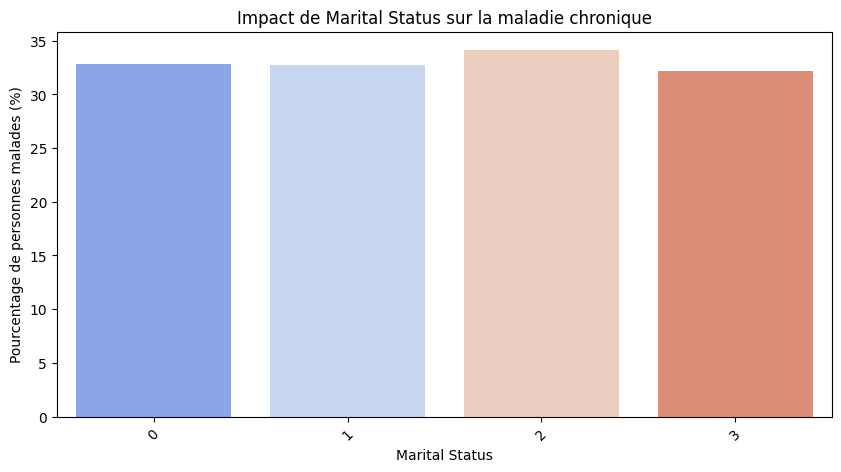


 Répartition pour : Education Level


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Education Level                                 
0                           66.876319  33.123681
1                           66.990837  33.009163
2                           67.200734  32.799266
3                           67.296118  32.703882
4                           67.136459  32.863541


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


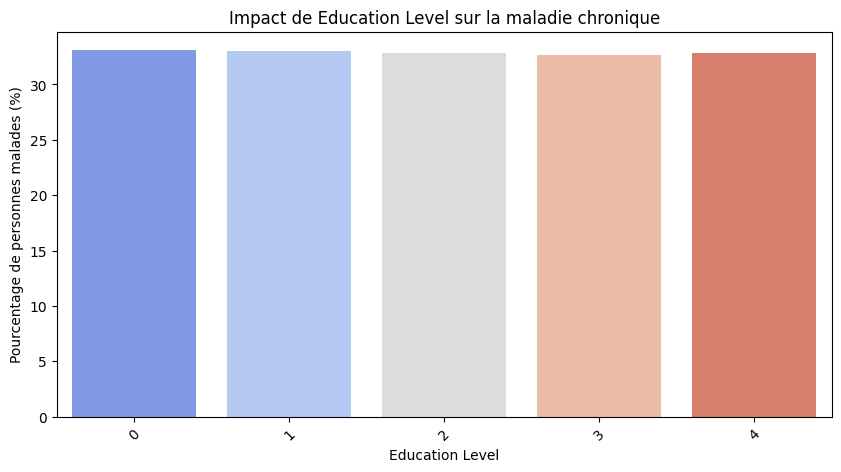


 Répartition pour : Number of Children


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Number of Children                              
0                           66.530741  33.469259
1                           67.364909  32.635091
2                           67.508724  32.491276
3                           67.476031  32.523969
4                           66.744662  33.255338


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


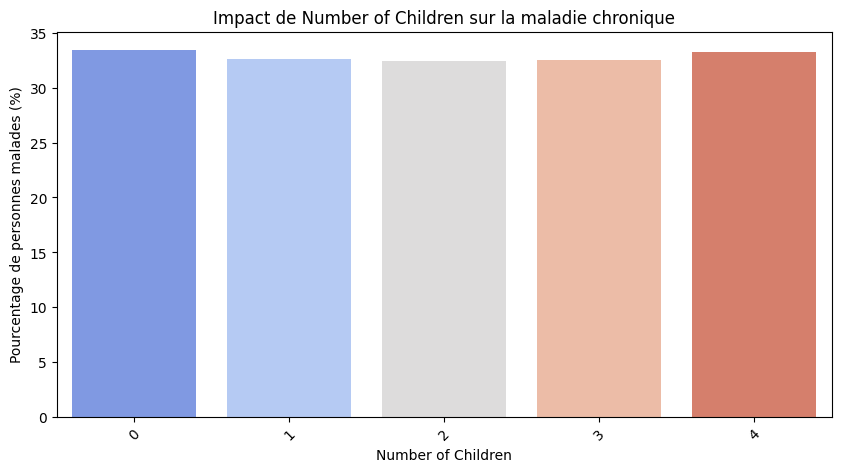


 Répartition pour : Smoking Status


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Smoking Status                                  
0                           60.365173  39.634827
1                           67.994732  32.005268
2                           68.014195  31.985805


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


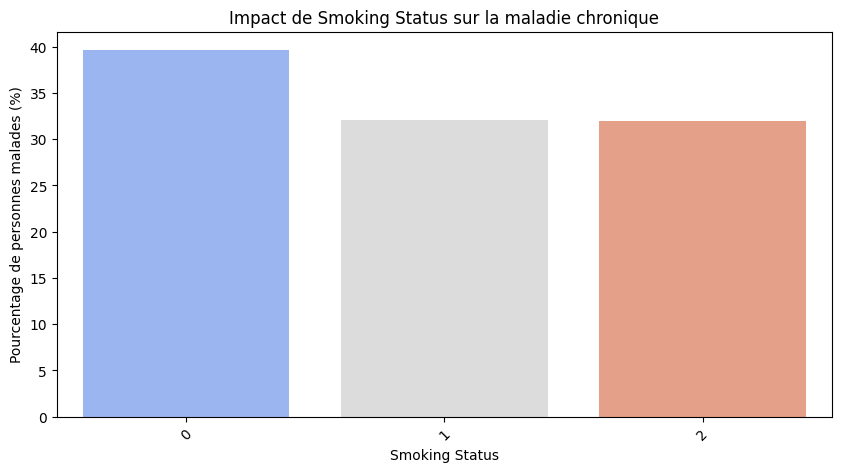


 Répartition pour : Physical Activity Level


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Physical Activity Level                         
0                           69.021770  30.978230
1                           65.572453  34.427547
2                           65.753755  34.246245


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


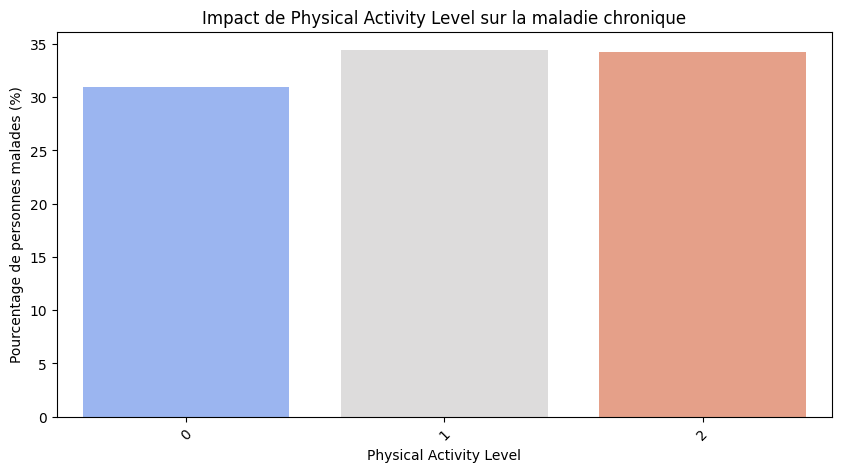


 Répartition pour : Employment Status


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Employment Status                               
0                           68.569482  31.430518
1                           64.412021  35.587979


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


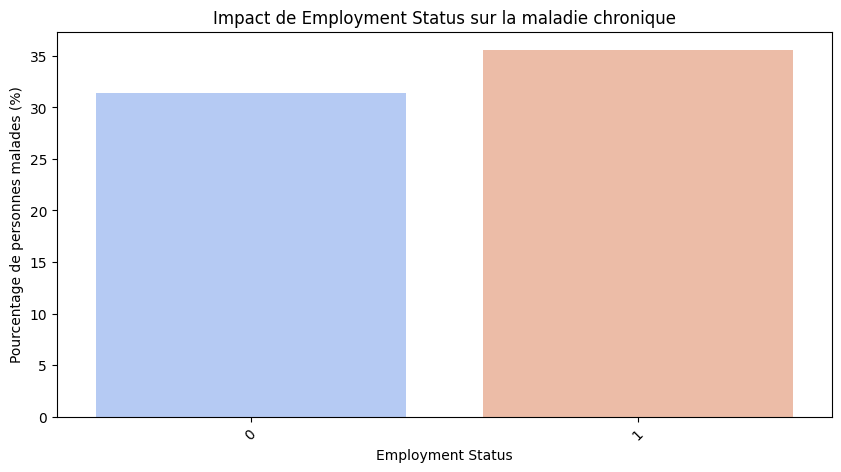


 Répartition pour : Alcohol Consumption


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Alcohol Consumption                             
0                           67.615081  32.384919
1                           67.419857  32.580143
2                           65.765053  34.234947


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


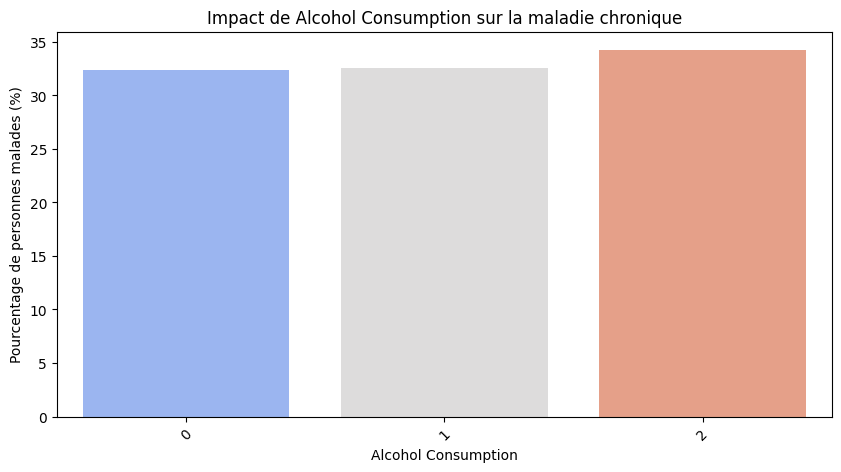


 Répartition pour : Dietary Habits


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Dietary Habits                                  
0                           67.569387  32.430613
1                           67.304014  32.695986
2                           65.407903  34.592097


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


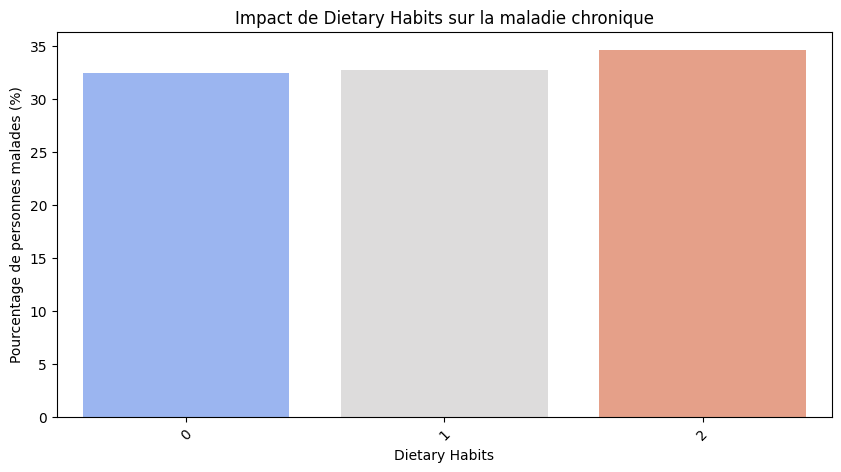


 Répartition pour : Sleep Patterns


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
Sleep Patterns                                  
0                           65.966724  34.033276
1                           67.343703  32.656297
2                           68.143071  31.856929


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


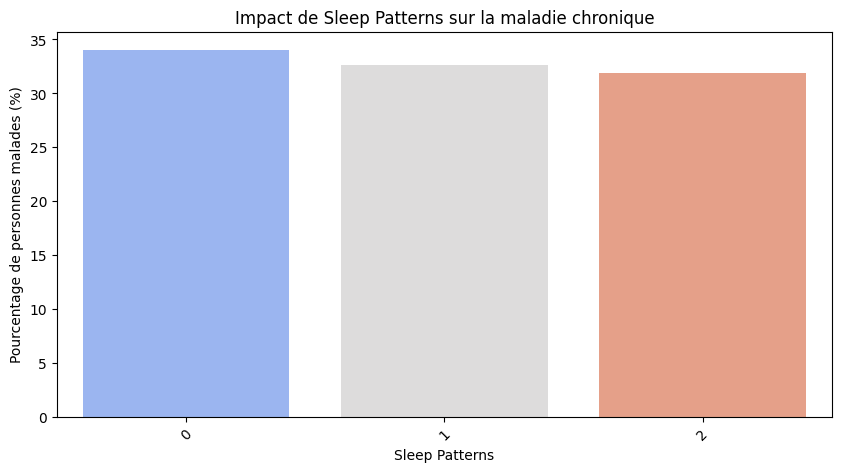


 Répartition pour : History of Mental Illness


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
History of Mental Illness                       
0                           67.268869  32.731131
1                           66.652096  33.347904


C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")


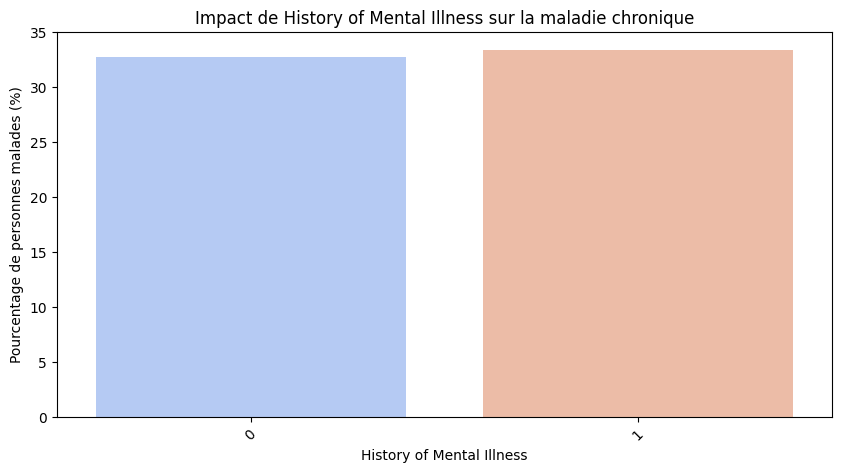

C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")



 Répartition pour : History of Substance Abuse


Pourcentage dans chaque catégorie :
 Chronic Medical Conditions          0          1
History of Substance Abuse                      
0                           67.185833  32.814167
1                           66.850289  33.149711


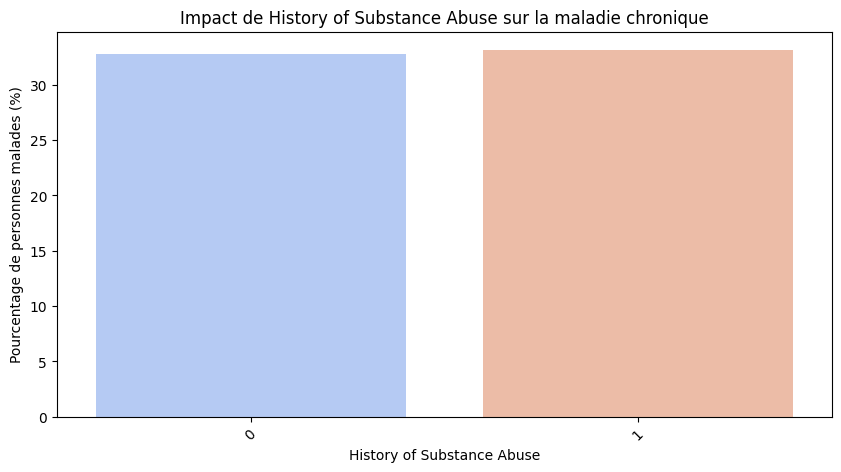


 Répartition pour : Family History of Depression



C:\Users\manac\AppData\Local\Temp\ipykernel_8516\1929584658.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")



Pourcentage dans chaque catégorie :
 Chronic Medical Conditions            0          1
Family History of Depression                      
0                             67.016512  32.983488
1                             67.257512  32.742488


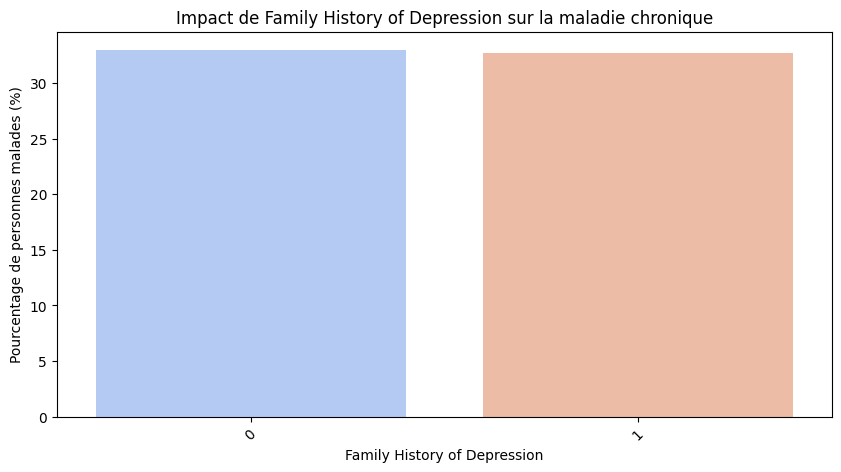

In [25]:
# Liste des colonnes à analyser (toutes sauf la cible)
cols_to_check = df.columns.tolist()
cols_to_check.remove("Chronic Medical Conditions")  # Exclure la colonne cible

for col in cols_to_check:
    if col == "Age" or col == "Income":
        continue
    else:
        print(f"\n Répartition pour : {col}\n")

        # Tableau croisé avec les **comptes bruts**
        counts = pd.crosstab(df[col], df["Chronic Medical Conditions"])
        
        # Tableau croisé avec **pourcentage par ligne**
        percentages = pd.crosstab(df[col], df["Chronic Medical Conditions"], normalize="index") * 100
        
        # Affichage des résultats
        print("\nPourcentage dans chaque catégorie :\n", percentages)
        
        # **Visualisation avec Seaborn**
        plt.figure(figsize=(10, 5))
        sns.barplot(x=percentages.index, y=percentages[1], palette="coolwarm")
        plt.xlabel(col)
        plt.ylabel("Pourcentage de personnes malades (%)")
        plt.title(f"Impact de {col} sur la maladie chronique")
        plt.xticks(rotation=45)
        plt.show()


In [ ]:
# Séparation X / y

X = df.drop(["Chronic Medical Conditions"], axis=1)
y = df["Chronic Medical Conditions"]

print("Prétraitement terminé !")

Prétraitement terminé !


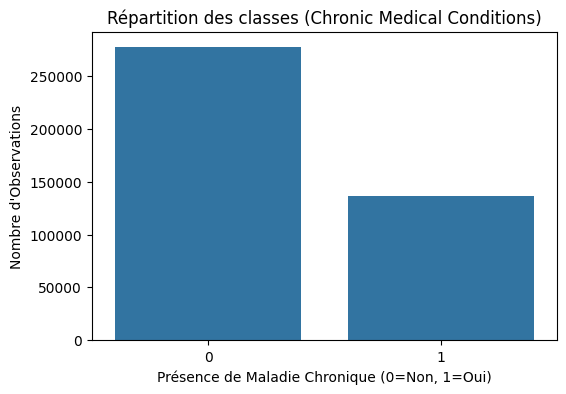

Chronic Medical Conditions
0    277561
1    136207
Name: count, dtype: int64


In [30]:
# Afficher la répartition des classes
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Répartition des classes (Chronic Medical Conditions)")
plt.xlabel("Présence de Maladie Chronique (0=Non, 1=Oui)")
plt.ylabel("Nombre d'Observations")
plt.show()
print(y.value_counts())  # Vérifier la répartition des classes

In [31]:
# Calcul du pourcentage pour chaque valeur de la colonne cible
target_counts = df['Chronic Medical Conditions'].value_counts(normalize=True) * 100

# Affichage
print(target_counts)


Chronic Medical Conditions
0    67.081311
1    32.918689
Name: proportion, dtype: float64


## **Ce que je comprends après avoir vu les sous-groupes est que les sous-groupe de chaque catégorie ont approximativement le même pourcentage de personnes ayant la maladie.**

## **Si on considère le cas de la colonne âge, si on considère les 2 extrémités c'est-à-dire les personnes âgées de 18 ans (min) et les personnes âgées de 80ans (max) on voit que le pourcentage est approximativement pareil et même que le pourcentage de jeunes ayant la maladie est plus élevé que celui des personnes âgées ayant la maladie. Alors que nous savons que dans les chiffres réels, les personnes âgées ont le plus de pourcentage de maladies chroniques. Ce qui me puosse à dire qu'il y'a vraiment un souci avec les données du dataset.**

# **Algorithmes d'apprentissage**

----
# <font color = "orange" style="bold">
# **1 - Random Forest**
# </font>
---

In [ ]:
""" # Séparation des données
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)
"""
X = df.drop(columns='Chronic Medical Conditions')
y = df['Chronic Medical Conditions']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Gestion du déséquilibre des classes avec SMOTE
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Séparation train / test
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, shuffle=True, random_state=42)

# Initialisation du modèle
model = RandomForestClassifier(
    n_estimators=1000,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    learning_rate=0.05
    )
model.fit(X_train, y_train)

""" # Importance des variables
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns)
feature_importances = feature_importances.sort_values(ascending=False)
print(feature_importances) """

# Prédictions
y_pred = model.predict(X_test)


In [41]:
# Évaluation du modèle
print(classification_report(y_test, y_pred))
print("AUC-ROC Score :", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred))

# Feature importance
features = pd.DataFrame(model.feature_importances_, index=X.columns, columns=['Importance']).sort_values(by='Importance', ascending=False)
print(features)

              precision    recall  f1-score   support

           0       0.63      0.76      0.69     83323
           1       0.69      0.55      0.61     83214

    accuracy                           0.65    166537
   macro avg       0.66      0.65      0.65    166537
weighted avg       0.66      0.65      0.65    166537

AUC-ROC Score : 0.6982326660045249
Matrice de confusion :
 [[63012 20311]
 [37386 45828]]
                              Importance
Smoking Status                  0.157849
Sleep Patterns                  0.122144
History of Substance Abuse      0.111124
Family History of Depression    0.098349
History of Mental Illness       0.097206
Alcohol Consumption             0.087247
Number of Children              0.079386
Physical Activity Level         0.050386
Dietary Habits                  0.048311
Marital Status                  0.046650
Income                          0.042908
Age                             0.030743
Education Level                 0.018445
Employmen

----
# <font color = "orange" style="bold">
# **2 - XGBoost**
# </font>
---

In [ ]:
model = XGBClassifier(max_depth=4, n_estimators=50000, learning_rate=0.05,reg_lambda=1, reg_alpha=0.1)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)[:, 1]

# Score d'entraînement
train_score = model.score(X_train, y_train)
print("Score d'entraînement:", train_score)

# Score de test
test_score = model.score(X_test, y_test)
print("Score de test:", test_score)

auc_roc = roc_auc_score(y_test, y_pred)
print(f"AUC-ROC Score : {auc_roc}")

# Feature importance
features = pd.DataFrame(model.feature_importances_, index=X.columns, columns=['Importance']).sort_values(by='Importance', ascending=False)
print(features)


Score d'entraînement: 0.7299612697350644
Score de test: 0.6636903510931504
AUC-ROC Score : 0.7156032845945852
                              Importance
Marital Status                  0.122084
History of Substance Abuse      0.112422
Employment Status               0.108176
Smoking Status                  0.097716
History of Mental Illness       0.097281
Family History of Depression    0.095974
Sleep Patterns                  0.092046
Alcohol Consumption             0.063249
Physical Activity Level         0.050688
Dietary Habits                  0.048713
Number of Children              0.048008
Education Level                 0.028187
Age                             0.020905
Income                          0.014551


## **Avec XGBoost, j'ai un score à l'entraînement de 72.99% sensiblement égal à 73%.**

## **Cependant, j'ai un peu joué avec les hyperparamètres pour améliorer les performances de mon modèle. J'ai augementé la profondeur de l'arbre à 4 (max_depth=4) et le nombre d'estimateurs à 50000 (n_estimators=50000).**

## **J'ai choisi 4 pour que le modèle puisse mieux capturer les relations entre les données de mon dataset qui sont complèxes au vue de la matrice de correlation. Ça évite aussi un overfitting car un nombre élevé de max_depth peut entraîner un sur-apprentissage.**

## **J'ai également choisi 50000 pour n_estimators en sachant que c'était au-delà de la norme. Cependant cela m'a permis d'améliorer mes performances en parallèle avec un learning_rate faible que j'ai mis à 0.05. Il y'a également un risque d'overfitting mais avec un learning_rate faible cela est compensé.**


## **J'ai essayé de faire un DAG pour pouvoir comprendre la relation en terme de causalité mais j'ai eu des problèmes avec l'installation et l'import des librairies. Le plan était d'utiliser DAG-GNN pour une découverte causale car mes données ne sont pas linéaires. C'est donc le plus adapté dans mon cas pour ce type de découverte. Ensuite j'aurais choisi les colonnes qui ont vraiment un impact sur la prédiction de la maladie.**

## **Pour l'encodage j'ai décidé d'encoder chaque type de variable selon l'encodage le plus approprié selon moi. Car les algorithmes tels que Random Forest donnent plus d'importance à des variables telle que income. Mais en réalité ils ne sont pas sensibles à l'échelle des données donc juste par précaution et souci de bonne pratique j'ai donc fait le scaling.**

## **J'ai essayé d'observer les features les plus importantes selon le modèle utilisé et j'ai eu les résultats ci-hauts.**

# **J'ai utilisé SMOTE pour pouvoir équilibrer mes données car on a à peu près 67% de gens qui ne sont pas malades contre 33% à peu près de gens qui sont malades. Et le paradoxe est que les sous-groupes ont à peu près le même distribution. Alors que si on remarque en réalité on ne peut pas avoir 31% environ des personnes âgées de 80 ans ont la maldie et 35% environ de ceux qui ont 18 ans ont la maladie ce qui est logiquement erronné. Cependant avant l'utilisation de SMOTE mes résultats étaaient relativement faibles et les métriques F1-Score et Recall étaient nuls et après avoir utilisé SMOTE j'ai eu des résultats pas très forts mais se sont améliorés, donc d'après moi le souci viendrait du déséquilibre des données.**

----
# <font color = "orange" style="bold">
# **3 - XGBoost avec les features de plus de 9% d'importance**
# </font>
---

In [48]:
X = df[["Marital Status", "History of Substance Abuse", "Employment Status"]]
y = df["Chronic Medical Conditions"]

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Gestion du déséquilibre des classes avec SMOTE
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Séparation train / test
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, shuffle=True, random_state=42)

model = XGBClassifier(max_depth=4, n_estimators=50000, learning_rate=0.05,reg_lambda=1, reg_alpha=0.1)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)[:, 1]

# Score d'entraînement
train_score = model.score(X_train, y_train)
print("Score d'entraînement:", train_score)

# Score de test
test_score = model.score(X_test, y_test)
print("Score de test:", test_score)

auc_roc = roc_auc_score(y_test, y_pred)
print(f"AUC-ROC Score : {auc_roc}")

Score d'entraînement: 0.5224781973307633
Score de test: 0.5238099527133528
AUC-ROC Score : 0.527838678999571


# **Si on utilise les features les plus importantes selon XGBoost, on des performance faibles ce qui signifie que même les colonnes les moins significatives apportent de l'information utile pour la prédiction. Dans ce cas si on utilise toutes les features on obtient 71,56% de AUC score.**

----
# <font color = "orange" style="bold">
# **Conclusion**
# </font>
---

# **Il y'a des problèmes au niveau de l'équilibre des données même au niveau des sous-groupes, et il y'a plusieurs types de données dont l'encodage doit être fait de façon minutieuse. Avec ledéséquilibre j'ai utilisé SMOTE ce qui m'as permis d'avoir de meilleurs résultats. Cependant les algorithmes n'arrivent pas à identifier correctement les colonnes les plus importantes pour prédire la maladie. La correlation ne dit pas non plus grande chose sur les relation entre les features. La solution serait potentiellement et très probablement dans la découverte des relations causales avec DAG-GNN par exemple. Je n'ai malheuresement pas pu appliquer la découverte causale en raison de problèmes d'importation de librairies.**
